In [70]:
import os
import os.path as path

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PMC_NAME = "IntSch1TokenStall"
DATA_DIR = "../odata/"

BUSY_SIBLING_COLOR = 'blue'
IDLE_SIBLING_COLOR = 'orange'

def get_latest_csv_file(directory):
    csv_files = [f for f in os.listdir(directory) if f.endswith('.csv')]
    if not csv_files:
        raise FileNotFoundError("No CSV files found in the directory.")
    latest_file = max(csv_files, key=lambda f: path.getmtime(path.join(directory, f)))
    return path.join(directory, latest_file)

In [71]:
latest_csv = get_latest_csv_file(DATA_DIR)
print(f"Latest CSV file: {latest_csv}")
df = pd.read_csv(latest_csv)

Latest CSV file: ../odata/bench_20261104_153311_cpu0.csv


# Scheduler queue Contention

This section illustrates the significant increasement in latency of `mul` instructions
when a scheduler queue is FULL.

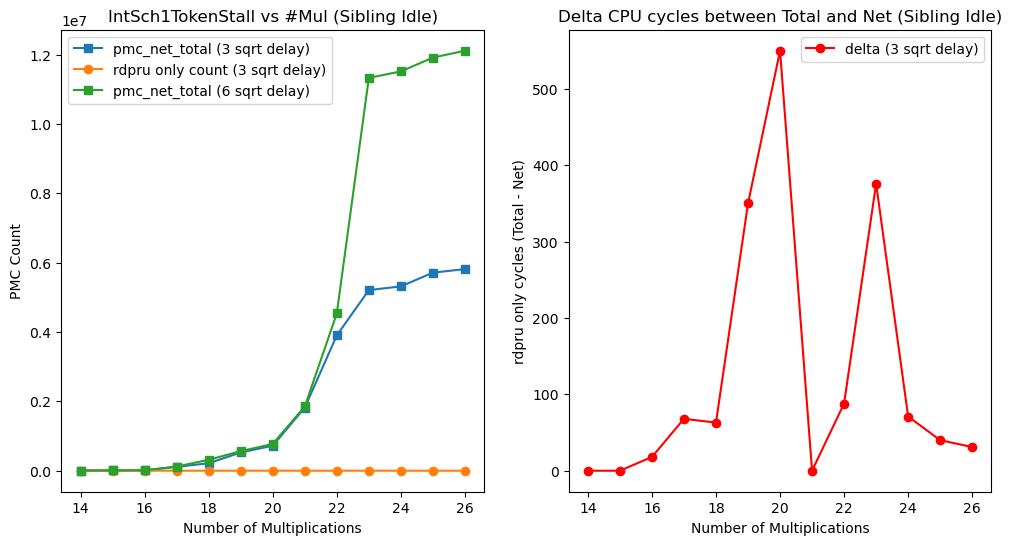

In [72]:
sibling_idle_df = df[df['sibling_state'] == 'idle']
# get vaules of 'pmc_net_per_region' and 'fill_entry' columns for sibling_idle_df

three_sqrt_delay_df = sibling_idle_df[sibling_idle_df['sqrt_delay'] == 3]
six_sqrt_delay_df = sibling_idle_df[sibling_idle_df['sqrt_delay'] == 6]


NORM_FACTOR = 1e5
x_vals = three_sqrt_delay_df[['fill_entry']].to_numpy()  # fill_entry
three_delay_net_count = three_sqrt_delay_df[['pmc_net_total']].to_numpy()   # pmc_net
three_delay_total_count = three_sqrt_delay_df[['pmc_body_total']].to_numpy()  # pmc_body_total
# y2_vals = three_sqrt_delay_df[['pmc_body_total']].to_numpy()  # pmc_body_total
three_delay_empty_count = three_sqrt_delay_df[['pmc_empty_total']].to_numpy()  # rdpru only count
six_delay_net_count = six_sqrt_delay_df[['pmc_net_total']].to_numpy()   # pmc_net

# Plotting the data
# side-by-side subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
ax1.plot(x_vals, three_delay_net_count, marker='s', label='pmc_net_total (3 sqrt delay)')
ax1.plot(x_vals, three_delay_empty_count, marker='o', label='rdpru only count (3 sqrt delay)')
ax1.plot(x_vals, six_delay_net_count, marker='s', label='pmc_net_total (6 sqrt delay)')
ax1.set_xlabel('Number of Multiplications')
ax1.set_ylabel('PMC Count')
ax1.set_title(f'{PMC_NAME} vs #Mul (Sibling Idle)')
ax1.legend()

ax2.plot(x_vals, three_delay_total_count - three_delay_net_count, marker='o', color='red', label='delta (3 sqrt delay)')
ax2.set_xlabel('Number of Multiplications')
ax2.set_ylabel('rdpru only cycles (Total - Net)')
ax2.set_title('Delta CPU cycles between Total and Net (Sibling Idle)')
ax2.legend()

plt.show()

`Total = rdpru overhead + Net (set of tested instructions)`

On Zen 3, we have 24 ALU1 entries for multiplications ONLY, that means mul instructions from thread MUST compete to each other for a single available slot of ALU1.

Addition and Substraction could be done in ALL four ALUs (ALU0-ALU3)

## Sibling Idle VS Sibling Busy

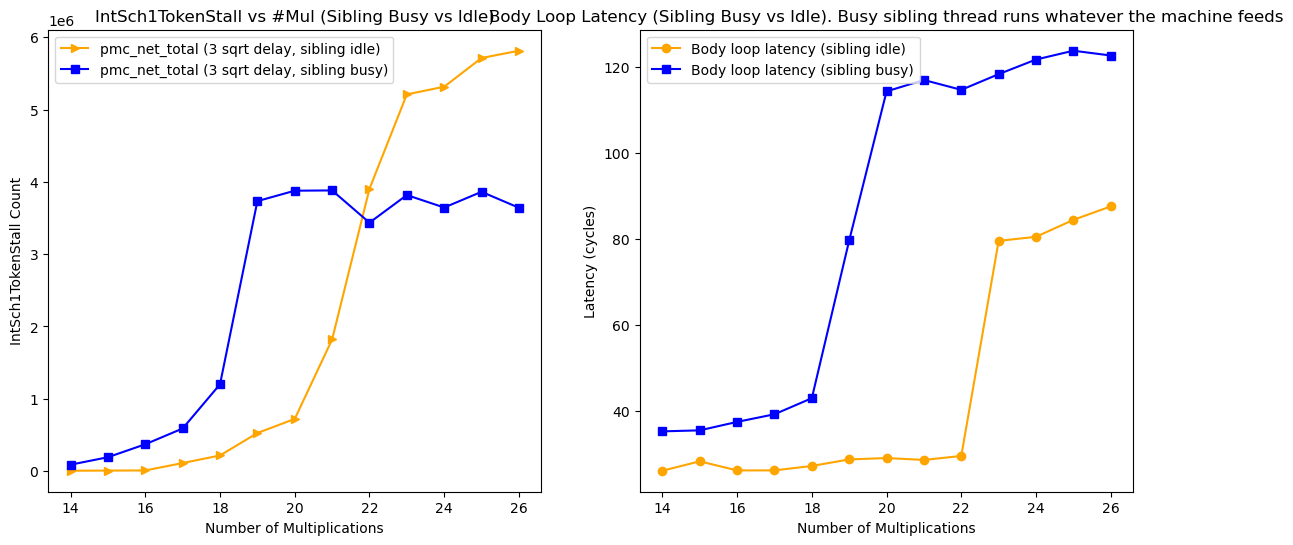

In [ ]:
sibling_busy_df = df[df['sibling_state'] == 'busy']

three_sqrt_delay_busy_df = sibling_busy_df[sibling_busy_df['sqrt_delay'] == 3]
six_sqrt_delay_busy_df = sibling_busy_df[sibling_busy_df['sqrt_delay'] == 6]

x_vals_busy = three_sqrt_delay_busy_df[['fill_entry']].values  # fill_entry
three_delay_net_count_busy = three_sqrt_delay_busy_df[['pmc_net_total']].values   # pmc_net
three_delay_total_count_busy = three_sqrt_delay_busy_df[['pmc_body_total']].values  # pmc_body_total
three_delay_empty_count_busy = three_sqrt_delay_busy_df[['pmc_empty_total']].values  # rdpru only count

six_delay_net_count_busy = six_sqrt_delay_busy_df[['pmc_net_total']].values   # pmc_net

# Get data of time latency of an empty loop (no multiplication) for sibling busy and idle
# (1-D arrays: errorbar() rejects the (n, 1) shape produced by df[['col']].values)
body_loop_idle_median = three_sqrt_delay_df['body_median'].to_numpy()
body_loop_idle_stddev = three_sqrt_delay_df['body_stddev'].to_numpy()
body_loop_idle_mean = three_sqrt_delay_df['body_mean'].to_numpy()

# Busy sibling
body_loop_busy_median = three_sqrt_delay_busy_df['body_median'].to_numpy()
body_loop_busy_stddev = three_sqrt_delay_busy_df['body_stddev'].to_numpy()
body_loop_busy_mean = three_sqrt_delay_busy_df['body_mean'].to_numpy()

assert len(body_loop_idle_median) == len(body_loop_busy_median), "Mismatch in lengths of body loop latency data"
assert np.shape(body_loop_idle_median) == np.shape(body_loop_idle_stddev)
assert len(x_vals) == len(body_loop_idle_median), "Mismatch in lengths of x_vals and body loop latency data"

# Ploting the data between sibling busy and idle
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
ax1.plot(x_vals, three_delay_net_count, marker='>', color=IDLE_SIBLING_COLOR, label='pmc_net_total (3 sqrt delay, sibling idle)')
ax1.plot(x_vals, three_delay_net_count_busy, marker='s', color=BUSY_SIBLING_COLOR, label='pmc_net_total (3 sqrt delay, sibling busy)')

ax1.set_xlabel('Number of Multiplications')
ax1.set_ylabel(f'{PMC_NAME} Count')
ax1.set_title(f'{PMC_NAME} vs #Mul (Sibling Busy vs Idle)')
ax1.legend()

# ax2.errorbar(x_vals.ravel(), body_loop_idle_median, yerr=body_loop_idle_stddev, fmt='o', label='Body loop latency (sibling idle)', capsize=5)
# ax2.errorbar(x_vals.ravel(), body_loop_busy_median, yerr=body_loop_busy_stddev, fmt='s', label='Body loop latency (sibling busy)', capsize=5)
ax2.plot(x_vals, body_loop_idle_mean, marker='o', color=IDLE_SIBLING_COLOR, label='Body loop latency (sibling idle)')
ax2.plot(x_vals, body_loop_busy_mean, marker='s', color=BUSY_SIBLING_COLOR, label='Body loop latency (sibling busy)')
ax2.set_xlabel('Number of Multiplications')
ax2.set_ylabel('Latency (cycles)')
ax2.set_title('Body Loop Latency (Sibling Busy vs Idle). Busy sibling thread runs empty loop')
ax2.legend()

plt.show()